# Application of Dirichlet boundary conditions
In this section, we will cover how one applies strong Dirichlet conditions to a variational problem.

## Problem specification
We consider the equations of linear elasticity,

$$
\begin{align}
-\nabla \cdot \sigma (u) &= f && \text{in } \Omega\\
u &= u_D && \text{on } \partial\Omega_D\\
\sigma(u) \cdot n &= T && \text{on } \partial \Omega_N
\end{align}
$$

where

$$
\begin{align}
\sigma(u)&= \lambda \mathrm{tr}(\epsilon(u))I + 2 \mu \epsilon(u)\\
\epsilon(u) &= \frac{1}{2}\left(\nabla u + (\nabla u )^T\right)
\end{align}
$$

where $\sigma$ is the stress tensor, $f$ is the body force per unit volume,
$\lambda$ and $\mu$ are Lamé's elasticity parameters for the material in $\Omega$,
$I$ is the identity tensor, $\mathrm{tr}$ is the trace operator on a tensor,
$\epsilon$ is the symmetric strain tensor (symmetric gradient),
and $u$ is the displacement vector field. Above we have assumed isotropic elastic conditions.
```{admonition} Parallels to previous lecture
:class: dropdown
The only difference between this formulation and the one in {ref}`functionals` is that we have added a
potential traction force on the boundary.
One can easily adapt the energy minimization problem for this.
```

We will consider a beam of dimensions $[0,0,0] \times [L,W,H]$, where

$$
\begin{align}
u_D(0,y,z) &= (0,0,0)\\
u_D(L,y,z) &= (0,0,-g)\\
\end{align}
$$

where $g$ is a prescribed displacement.
In other words we are clamping the beam on one end, and applying a given displacement on the
other end.
All other boundaries will be traction free, i.e. $T=(0,0,0)$.


tdim = 3
facet_marker.dim = 2


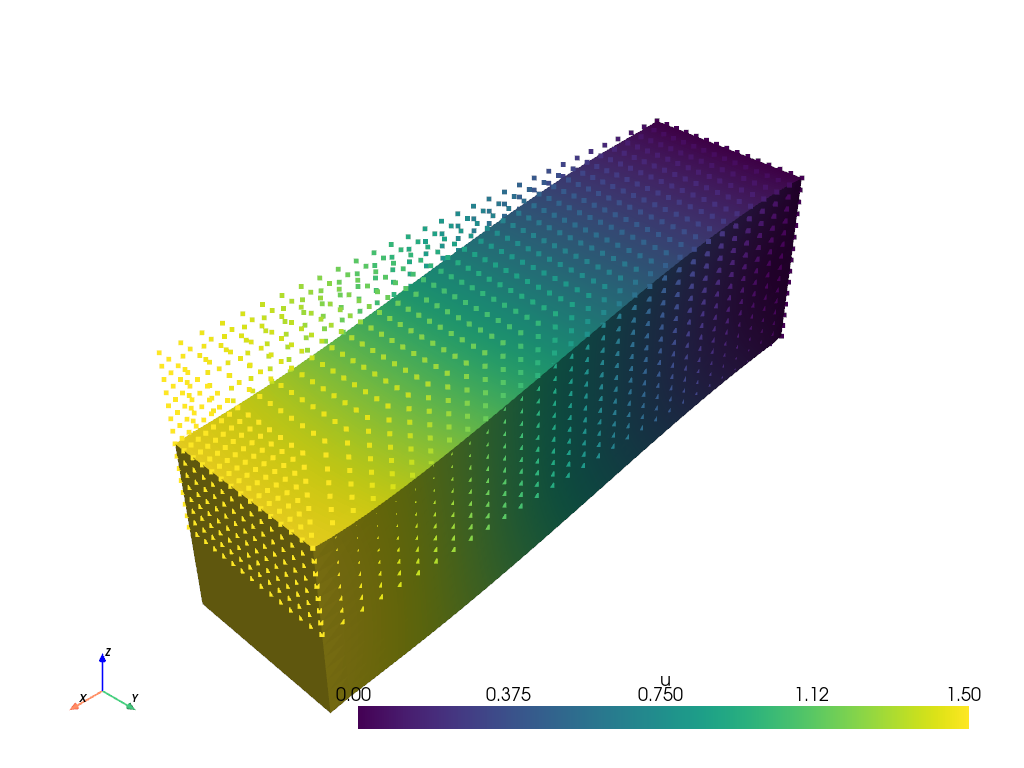

Matrix A is symmetric after assembly: True
Matrix A is symmetric after bc application: False
Matrix is symmetric after lifting assembly: True


In [5]:
from mpi4py import MPI
from petsc4py import PETSc

import numpy as np

import dolfinx
import dolfinx.fem.petsc
import ufl

L = 10.0
W = 3.0
H = 3.0

mesh = dolfinx.mesh.create_box(
    MPI.COMM_WORLD,
    [[0.0, 0.0, 0.0], [L, W, H]],
    [15, 7, 7],
    cell_type=dolfinx.mesh.CellType.hexahedron,
)
tdim = mesh.topology.dim

print(f"tdim = {tdim}")

V = dolfinx.fem.functionspace(mesh, ("Lagrange", 2, (mesh.geometry.dim,)))

# ## Locate exterior facets
# We start by locate the various facets for the different boundary conditions.
# First, we find all boundary facets (those facets that are connected to only one cell)

mesh.topology.create_connectivity(tdim - 1, tdim)
boundary_facets = dolfinx.mesh.exterior_facet_indices(mesh.topology)

# ## Locate subset of exterior facets

# Next we find those facets that should be clamped, and those that should have a non-zero traction on it.
# We pass in a Python function that takes in a `(3, num_points)` array, and returns an 1D array of booleans
# indicating if the point satisfies the condition or not.

# Here we find the facets on the right boundary, where $x = 0$
def left_facets(x):
    return np.isclose(x[0], 0.0) # isclose, dove le x[0] sono uguali a zero


clamped_facets = dolfinx.mesh.locate_entities_boundary(mesh, tdim - 1, left_facets)

# An equivalent way to find the facets is to use Python `lambda` functions, which are [anonymous functions](https://docs.python.org/3/glossary.html#term-lambda)
# (they are not bound to a variable name).

# Here we find the facets on the right boundary, where $x = L$
prescribed_facets = dolfinx.mesh.locate_entities_boundary(mesh, tdim - 1, lambda x: np.isclose(x[0], L)) # dove x[0] sono uguali a L

# As all mesh entities are represented as integers, we can find the boundary facets by
# remaining facets using numpy set operations

free_facets = np.setdiff1d(boundary_facets, np.union1d(clamped_facets, prescribed_facets))

# ## Defining a mesh marker
# Next, we can define a meshtag object for all the facets in the mesh

num_facets = mesh.topology.index_map(tdim - 1).size_local
markers = np.zeros(num_facets, dtype=np.int32)
clamped = 1
prescribed = 2
free = 3
markers[clamped_facets] = clamped
markers[prescribed_facets] = prescribed
markers[free_facets] = free
facet_marker = dolfinx.mesh.meshtags(mesh, tdim - 1, np.arange(num_facets, dtype=np.int32), markers)

# ## The variational formulation
# We have now seen this variational formulation a few times

x = ufl.SpatialCoordinate(mesh)
T_0 = dolfinx.fem.Constant(mesh, (0.0, 0.0, 0.0))
E = dolfinx.fem.Constant(mesh, 1.4e3)
nu = dolfinx.fem.Constant(mesh, 0.3)
mu = E / (2.0 * (1.0 + nu))
lmbda = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu)) # = G, shear modulus
f = dolfinx.fem.Constant(mesh, (0.0, 0.0, 0.0))

# compatibility
def epsilon(u):
    return ufl.sym(ufl.grad(u))

# costitutive
def sigma(u):
    return 2.0 * mu * epsilon(u) + lmbda * ufl.tr(epsilon(u)) * ufl.Identity(len(u))

ds = ufl.Measure("ds", domain=mesh, subdomain_data=facet_marker)
u = ufl.TrialFunction(V)
v = ufl.TestFunction(V)
a = ufl.inner(sigma(u), epsilon(v)) * ufl.dx
L = ufl.inner(f, v) * ufl.dx + ufl.inner(T_0, v) * ds(3)

# ## Defining a Dirichlet condition
# We have already identified what facets that should have Dirichet conditions applied to them.
# We now need to find all degrees of freedom associated with these facets.
#
# ### Exercise
# - How many degrees of freedom are associated with each facet in this case?
# - How many degrees of freedom is in the closure of each facet (i.e. the set of all dofs associated) with a sub-entity
#   of lower topological dimension that is part of the facet (i.e. a vertex or an edge).
#
# We can find these dofs by using `dolfinx.fem.locate_dofs_topological`.
# This function takes in the function space we want to identify the dofs in, the entities we want to find the dofs for,
# and the dimension of the entity.
# We simply access the through the `facet_marker` object.

clamped_dofs = dolfinx.fem.locate_dofs_topological(V, facet_marker.dim, facet_marker.find(clamped))
displaced_dofs = dolfinx.fem.locate_dofs_topological(V, facet_marker.dim, facet_marker.find(prescribed))

print(f"facet_marker.dim = {facet_marker.dim}")

# Next, we define the prescribed displacement

u_prescribed = dolfinx.fem.Constant(mesh, (0.0, 0.0, -H / 2))
u_clamped = dolfinx.fem.Constant(mesh, (0.0, 0.0, 0.0))

# We define the Dirichlet boundary condition object as

bcs = [
    dolfinx.fem.dirichletbc(u_clamped, clamped_dofs, V),
    dolfinx.fem.dirichletbc(u_prescribed, displaced_dofs, V),
]

# In most situations, you would just pass this object to the linear problem and it would be handled for you

petsc_options = {
    "ksp_type": "preonly",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps",
}
problem = dolfinx.fem.petsc.LinearProblem(a, L, bcs=bcs, petsc_options=petsc_options)
u = problem.solve()
u.x.scatter_forward()

import pyvista
pyvista.start_xvfb(1.2)
grid = dolfinx.plot.vtk_mesh(u.function_space)
pyvista_grid = pyvista.UnstructuredGrid(*grid)
values = u.x.array.reshape(-1, 3)
pyvista_grid.point_data["u"] = values
warped = pyvista_grid.warp_by_vector("u")
plotter = pyvista.Plotter()
plotter.show_axes()
plotter.add_mesh(pyvista_grid, style="points")
plotter.add_mesh(warped, scalars="u", lighting=True)
if not pyvista.OFF_SCREEN:
    plotter.show()

# However, what goes on under the hood?

# In this section we will explore two ways of applying boundary conditions,
# **the identity row approach** and the **lifting approach**.
# Under the hood in DOLFINx we always use the lifting approach, but we will show how to use the identity row approach,
# to motivate why we prefer lifting.
#
# ## The unconstrained problem matrix
#
# If the problem had been unconstrained, we would assemble the stiffness matrix as

a_compiled = dolfinx.fem.form(a)
A = dolfinx.fem.petsc.assemble_matrix(a_compiled)
A.assemble()

# which is symmetric due to the symmetry of the stress tensor.

print(f"Matrix A is symmetric after assembly: {A.isSymmetric(1e-5)}")

# Let us split the degrees of freedom into two disjoint sets, $u_d$, and $u_{bc}$, and set up the corresponding linear system
#
# $$
# \begin{align}
# \begin{pmatrix}
# A_{d,d} & A_{d, bc} \\
# A_{bc,d} & A_{bc, bc}
# \end{pmatrix}
# \begin{pmatrix}
# u_d \\
# u_{bc}
# \end{pmatrix}
# &=
# \begin{pmatrix}
# b_d \\
# b_{bc}
# \end{pmatrix}
# \end{align}
# $$ (A_unconstrained)
#
# ## Identity row approach

# In the identity row approach, we set the rows corresponding to the Dirichlet conditions to the identity row
# and set the appropriate dofs on the right hand side to contain the Dirichlet values:
#
# $$
# \begin{align}
# \begin{pmatrix}
# A_{d,d} & A_{d, bc} \\
# 0 & I
# \end{pmatrix}
# \begin{pmatrix}
# u_d \\
# u_{bc}
# \end{pmatrix}
# &=
# \begin{pmatrix}
# b_d \\
# g
# \end{pmatrix}
# \end{align}
# $$
#
# where $g$ is the vector satisfying the various Dirichlet conditions.

# We do this with DOLFINx in the following way

for bc in bcs:
    dofs, _ = bc._cpp_object.dof_indices()
    A.zeroRowsLocal(dofs, diag=1)

# Next, we assemble the RHS vector as normal and set the BC values

L_compiled = dolfinx.fem.form(L)
b = dolfinx.fem.petsc.assemble_vector(L_compiled)
b.ghostUpdate(addv=PETSc.InsertMode.ADD_VALUES, mode=PETSc.ScatterMode.REVERSE)
dolfinx.fem.petsc.set_bc(b, bcs)
b.ghostUpdate(addv=PETSc.InsertMode.INSERT_VALUES, mode=PETSc.ScatterMode.FORWARD)

# We can now solve the linear system.
# However, we now have explicit an explicit PETSc matrix `A` and a vector `b`
# Then, the most common approach is to create a `PETSc.KSP` object.
# Press the following dropdown to see how you can define a PETSc KSP object.

# + tags=["hide-input"]
uh = dolfinx.fem.Function(V)
solver = PETSc.KSP().create(mesh.comm)
solver.setOperators(A)
solver.setType(PETSc.KSP.Type.PREONLY)
solver.getPC().setType(PETSc.PC.Type.LU)
solver.getPC().setFactorSolverType("mumps")
solver.solve(b, uh.x.petsc_vec)
uh.x.petsc_vec.ghostUpdate(addv=PETSc.InsertMode.INSERT_VALUES, mode=PETSc.ScatterMode.FORWARD)

# We verify that this yields the same solution as using linear problem
assert np.allclose(u.x.array, uh.x.array)
# -

# ### Symmetry of the matrix
# We note that matrix `A` is no longer symmetric, meaning that we exclude a whole class of iterative solvers
# ([Conjugate Gradient](https://en.wikipedia.org/wiki/Conjugate_gradient_method)).

print(f"Matrix A is symmetric after bc application: {A.isSymmetric(1e-5)}")

# Is there an alternative way to solve this that can preserve symmetry?

# ## Lifting
# Lifting is a procedure that can be use to reduce the number of unknowns in the system,
# to only be the dofs unconstrained degrees of freedom.
# We start with {eq}`A_unconstrained`, but we insert $u_{bc}=g$ in the first row of the system to get the equation
# \begin{align}
# A_{d,d}
# u_d
# &=
# b_d
# -
# A_{d, bc}g
# \end{align}
# and we end up with a smaller system, which is symmetric if $A_{d,d}$ is symmetric.
# However, we do not want to remove the degrees of freedom from the sparse, matrix, as it makes the matrix
# less adaptable for varying boundary conditions, so we set up the system
# \begin{align}
# \begin{pmatrix}
# A_{d,d} & 0 \\
# 0 & I
# \end{pmatrix}
# \begin{pmatrix}
# u_d \\
# u_{bc}
# \end{pmatrix}
# &=
# \begin{pmatrix}
# b_d - A_{d,bc}g \\
# g
# \end{pmatrix}
# \end{align}
# We do this in DOLFINx with the following commands
#
# 1. `assemble_matrix` with Dirichlet conditions

A_lifting = dolfinx.fem.petsc.assemble_matrix(a_compiled, bcs=bcs)
A_lifting.assemble()

# converts all columns and rows with a Dirichlet dofs to the identity row/column (during local assembly.
# 2. `assemble_vector` without dirichletbc

b_lifting = dolfinx.fem.petsc.assemble_vector(L_compiled)

# 3. `apply_lifting`, i.e subtract $A_{d,bc}g$ from the vector

dolfinx.fem.petsc.apply_lifting(b_lifting, [a_compiled], bcs=[bcs])
b_lifting.ghostUpdate(addv=PETSc.InsertMode.ADD_VALUES, mode=PETSc.ScatterMode.REVERSE)

# 4. `set_bc`, i.e set the degrees of freedom for known dofs

dolfinx.fem.petsc.set_bc(b_lifting, bcs)
b_lifting.ghostUpdate(addv=PETSc.InsertMode.INSERT_VALUES, mode=PETSc.ScatterMode.FORWARD)

print(f"Matrix is symmetric after lifting assembly: {A_lifting.isSymmetric(1e-5)}")

# We can verify that we get the same solution as wehn we used the identity row approach
# Press the following dropdown to reveal the verification

# + tags=["hide-input"]
solver.setOperators(A_lifting)
u_lifted = dolfinx.fem.Function(V)
solver.solve(b_lifting, u_lifted.x.petsc_vec)
u_lifted.x.petsc_vec.ghostUpdate(addv=PETSc.InsertMode.INSERT_VALUES, mode=PETSc.ScatterMode.FORWARD)

assert np.allclose(u_lifted.x.array, uh.x.array)
# -


# ## Extra material: Alternative lifting procedure
# The lifting procedure above is used in both C++ and Python, and what it does under the hood is to compute the local
# matrix-vector products of $A_{d, bc}$ and $g$ (no global matrix vector products are involved). However, we can use UFL
# to do this in a simpler fashion in Python

# + tags=["hide-output"]
g = dolfinx.fem.Function(V)
g.x.array[:] = 0
dolfinx.fem.set_bc(g.x.array, bcs)
g.x.scatter_forward()
L_lifted = L - ufl.action(a, g)
# -

# What happens here?
#
# `ufl.action` reduces the bi-linear form to a linear form (and would reduce a linear form to a scalar)
#  by replacing the trial function with the function $g$, that is only non-zero at the Dirichlet condition

# The new assembly of the linear and bi-linear form would be

# + tags=["hide-output"]
A = dolfinx.fem.petsc.assemble_matrix(a_compiled, bcs=bcs)
A.assemble()
b_new = dolfinx.fem.petsc.assemble_vector(dolfinx.fem.form(L_lifted))
dolfinx.fem.petsc.set_bc(b_new, bcs)
b_new.ghostUpdate(addv=PETSc.InsertMode.INSERT_VALUES, mode=PETSc.ScatterMode.FORWARD)
# -

# Press the following dropdown to reveal the verification of this approach

# + tags=["hide-input"]
solver.setOperators(A)
u_new = dolfinx.fem.Function(V)
solver.solve(b_lifting, u_new.x.petsc_vec)
u_new.x.petsc_vec.ghostUpdate(addv=PETSc.InsertMode.INSERT_VALUES, mode=PETSc.ScatterMode.FORWARD)

assert np.allclose(u_new.x.array, u.x.array)
# -